## Curso Integral de Econometría 
### Econometría de datos panel con Python
### Tema: Estimador Between
### Sesión: 08
### Fecha: 07/11/2026
### Asesor: Alexis Adonai Morales Alberto

#### **Módulos, submódulos, clases y configuración de la sesión**

In [1]:
# Módulos y submódulos completos 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
import base64

In [2]:
# Clases a importar 

from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from pathlib import Path

In [3]:
# Configuración de directorios y parámetros

BASE = Path(
    "E:\Econometrics Data Lab\Curso integral de econometría\Datos de panel\PANEL_SEP26"
)
SALIDA = BASE / "Resultados" / "S08_Between"
SALIDA.mkdir(parents = True, exist_ok = True)
ALPHA = 0.05

#### **Carga de datos y definición de variables**

In [4]:
if "data_bank" in globals():
    Original = data_bank.copy()
    if not {"Bank_ID", "Year"}.issubset(Original.columns):
        Original = Original.reset_index()
else:
    candidatos = [BASE/"Datos/bank_panel_data.csv", BASE/"bank_panel_data.csv",
                  Path("Datos/bank_panel_data.csv"), Path("bank_panel_data.csv")]
    ruta = next((p for p in candidatos if p.is_file()), None)
    if ruta is None:
        raise FileNotFoundError("Coloca bank_panel_data.csv en Datos o junto al script.")
    Original = pd.read_csv(ruta)
Original = Original.drop(columns=["index"], errors="ignore")
explicativas = ["Revenue", "Assets", "Interest_Rate", "GDP_Growth"]
variables = ["Profit"] + explicativas
necesarias = ["Bank_ID", "Year"] + variables
if not set(necesarias).issubset(Original.columns):
    raise ValueError(f"Faltan columnas: {set(necesarias)-set(Original.columns)}")
Panel = Original.copy().replace(r"^\s*$", np.nan, regex=True)
for v in ["Year"] + variables:
    Panel[v] = pd.to_numeric(Panel[v], errors="raise")
Panel[["Year"]+variables] = Panel[["Year"]+variables].replace([np.inf,-np.inf],np.nan)
Excluidas_NA = Panel.loc[Panel[necesarias].isna().any(axis=1)].copy()
Panel = Panel.dropna(subset=necesarias).sort_values(["Bank_ID","Year"])
if Panel.empty or Panel.duplicated(["Bank_ID","Year"]).any():
    raise ValueError("Muestra vacía o duplicados banco-año.")
# Muestra común con >=2 periodos para comparar W y B. Between por sí solo
# admite sujetos con un periodo, pero no se mezclan muestras en esta comparación.
conteos = Panel.groupby("Bank_ID").size()
Excluidas_singleton = Panel.loc[Panel.Bank_ID.isin(conteos[conteos.eq(1)].index)].copy()
Panel = Panel.loc[~Panel.Bank_ID.isin(conteos[conteos.eq(1)].index)].reset_index(drop=True)
N, T, NT, K = Panel.Bank_ID.nunique(), Panel.Year.nunique(), len(Panel), len(explicativas)
P = K+1
if N <= 2*K+1 or NT <= N+K:
    raise ValueError("Pocos individuos/grados de libertad para el modelo y la comparación híbrida.")
Ti = Panel.groupby("Bank_ID").size().rename("T_i")
tabla_panel = Panel.groupby(["Bank_ID","Year"]).size().unstack(fill_value=0)
balanceado = bool(tabla_panel.eq(1).all().all())
print(f"N={N}; T={T}; NT={NT}; balanceado en muestra={balanceado}")
print(f"Filas excluidas por NA={len(Excluidas_NA)}; singletons={len(Excluidas_singleton)}")
print("Se usa la misma muestra para todos los estimadores comparados.")
if Panel.groupby("Year").GDP_Growth.nunique().gt(1).any():
    print("GDP_Growth varía entre bancos dentro del año; verificar definición y procedencia.")


N=20; T=9; NT=180; balanceado en muestra=True
Filas excluidas por NA=0; singletons=0
Se usa la misma muestra para todos los estimadores comparados.
GDP_Growth varía entre bancos dentro del año; verificar definición y procedencia.


#### **Promedios por individuo: Una fila por banco**

In [5]:
Medias = Panel.groupby("Bank_ID")[variables].mean()
Medias = Medias.join(Ti)
Medias["Year_min"] = Panel.groupby("Bank_ID").Year.min()
Medias["Year_max"] = Panel.groupby("Bank_ID").Year.max()
print("\nBase Between: una observación por banco\n", Medias.round(4).to_string())
print(f"El modelo between usa {N} filas, no {NT} observaciones independientes")


Base Between: una observación por banco
           Profit   Revenue     Assets  Interest_Rate  GDP_Growth  T_i  Year_min  Year_max
Bank_ID                                                                                  
1        46.5434  273.1123  2453.5922         2.7509      3.8637    9      2015      2023
2        52.5962  289.8420  2764.8983         2.4854      3.6429    9      2015      2023
3        44.7907  261.6090  3390.4657         2.3063      3.2407    9      2015      2023
4        84.3157  396.3256  3445.8745         2.0381      2.4358    9      2015      2023
5        40.0646  314.8162  3419.9203         3.4481      3.7834    9      2015      2023
6        53.8097  360.1953  3196.3615         2.8089      2.4834    9      2015      2023
7        39.9007  241.0589  3431.3511         3.4394      3.8470    9      2015      2023
8        56.2719  397.0024  3133.1279         3.5401      4.0403    9      2015      2023
9        51.8773  325.7712  3250.3623         3.5866      

#### **Estimación between manual y MCO sobre medias**

In [6]:
yB = Medias.Profit
XB = sm.add_constant(Medias[explicativas],has_constant="add")
if np.linalg.matrix_rank(XB.to_numpy()) < P:
    raise ValueError("Las medias individuales no tienen rango completo.")
beta_manual = pd.Series(np.linalg.lstsq(XB,yB,rcond=None)[0],index=XB.columns)
Between_clasico = sm.OLS(yB,XB).fit()
Between_HC3 = sm.OLS(yB,XB).fit(cov_type="HC3",use_t=True)
assert np.allclose(beta_manual,Between_clasico.params)
assert Between_clasico.nobs == N
assert Between_clasico.df_resid == N-P
print("\nResumen clásico (hipótesis de errores homocedásticos):\n",Between_clasico.summary())
ICB = Between_HC3.conf_int(alpha=ALPHA)
Tabla_between = pd.DataFrame({"Coeficiente":Between_HC3.params,
    "EE_clasico":Between_clasico.bse,"EE_HC3":Between_HC3.bse,
    "t_HC3":Between_HC3.tvalues,"p_HC3":Between_HC3.pvalues,
    "IC95_inf":ICB[0],"IC95_sup":ICB[1]})
print(f"\nTabla principal between: HC3, referencia t con {N-P} gl (aproximada)\n",Tabla_between.round(6).to_string())
print("HC3 permite heterocedasticidad entre bancos; no corrige endogeneidad ni dependencia entre bancos.")
for v in explicativas:
    print(f"\n{v}: bancos con una media de {v} una unidad mayor presentan "
          f"{Between_HC3.params[v]:.5f} unidades de diferencia en su beneficio medio, ceteris paribus.")
    print(f"H0: beta_B,{v}=0; H1: distinto de cero; p={Between_HC3.pvalues[v]:.6g}.")
print("La asociación ENTRE bancos no predice automáticamente el efecto de cambiar X en un banco.")
print("El intercepto corresponde a medias X=0; puede quedar fuera del soporte observado.")



Resumen clásico (hipótesis de errores homocedásticos):
                             OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.697
Model:                            OLS   Adj. R-squared:                  0.617
Method:                 Least Squares   F-statistic:                     8.645
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           0.000795
Time:                        10:25:17   Log-Likelihood:                -65.978
No. Observations:                  20   AIC:                             142.0
Df Residuals:                      15   BIC:                             146.9
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------

#### **Within y pooled sobre la misma muestra**

In [7]:
medias_alineadas = Panel.groupby("Bank_ID")[variables].transform("mean")
Dentro = Panel[variables] - medias_alineadas
Dentro.columns = [v+"_W" for v in variables]
Panel = pd.concat([Panel,Dentro],axis=1)
for v in explicativas:
    Panel[v+"_B"] = medias_alineadas[v]
formula = "Profit ~ Revenue + Assets + Interest_Rate + GDP_Growth"
Within_clasico = smf.ols(formula+" + C(Bank_ID)",data=Panel).fit()
Within_cluster = smf.ols(formula+" + C(Bank_ID)",data=Panel).fit(
    cov_type="cluster",cov_kwds={"groups":Panel.Bank_ID,
    "use_correction":True,"df_correction":True},use_t=True)
Pooled = smf.ols(formula,data=Panel).fit()
Comparacion = pd.DataFrame({"Pooled":Pooled.params[explicativas],
    "Within":Within_cluster.params[explicativas],"Between":Between_HC3.params[explicativas],
    "EE_Within_cluster":Within_cluster.bse[explicativas],"EE_Between_HC3":Between_HC3.bse[explicativas]})
print("\nComparación de pendientes e incertidumbre:\n",Comparacion.round(6).to_string())



Comparación de pendientes e incertidumbre:
                  Pooled    Within    Between  EE_Within_cluster  EE_Between_HC3
Revenue        0.188984  0.186825   0.229840           0.018786        0.062313
Assets         0.001407  0.001417   0.003847           0.001903        0.005660
Interest_Rate -0.820404  0.239859 -10.781301           1.886262        5.580719
GDP_Growth    -0.704851 -0.586677   3.540368           1.391508        6.360191


#### **Proyección between y ponderaciones $T_i$**

In [8]:
D = pd.get_dummies(Panel.Bank_ID,dtype=float).to_numpy()
PB = D @ np.linalg.solve(D.T@D,D.T)
MW = np.eye(NT)-PB
X = Panel[explicativas].to_numpy(); y=Panel.Profit.to_numpy()
assert np.allclose(PB.T,PB) and np.allclose(PB@PB,PB)
assert np.allclose(PB@D,D) and np.linalg.matrix_rank(PB)==N
assert np.allclose(PB@y,medias_alineadas.Profit)
assert np.allclose(PB@X,medias_alineadas[explicativas])
assert np.allclose(MW@PB,0,atol=1e-9)
# Repetir cada media T_i veces equivale en coeficientes a WLS con pesos T_i.
Between_Ti = sm.WLS(yB,XB,weights=Medias.T_i).fit()
repetido = sm.add_constant(PB@X,has_constant="add")
beta_repetida = np.linalg.lstsq(repetido,PB@y,rcond=None)[0]
assert np.allclose(beta_repetida,Between_Ti.params)
if balanceado:
    assert np.allclose(Between_Ti.params,Between_clasico.params)
print("\nBetween de igual peso por banco y ponderado por T_i:")
print(pd.DataFrame({"Igual_peso":Between_clasico.params,"Peso_Ti":Between_Ti.params}))
print("T_i NO es en general el peso eficiente de RE. Si Var(a_i)>0, "
      "la precisión ideal es proporcional a 1/(sigma_a²+sigma_u²/T_i), bajo sus supuestos.")
print("Las medias repetidas no crean nuevos individuos independientes; no usar EE ingenuos sobre esas filas.")



Between de igual peso por banco y ponderado por T_i:
               Igual_peso    Peso_Ti
const          -10.029859 -10.029859
Revenue          0.229840   0.229840
Assets           0.003847   0.003847
Interest_Rate  -10.781301 -10.781301
GDP_Growth       3.540368   3.540368
T_i NO es en general el peso eficiente de RE. Si Var(a_i)>0, la precisión ideal es proporcional a 1/(sigma_a²+sigma_u²/T_i), bajo sus supuestos.
Las medias repetidas no crean nuevos individuos independientes; no usar EE ingenuos sobre esas filas.


#### **Descomposición exacta de pooled**

In [9]:
Xglobal = X.mean(axis=0); yglobal = y.mean()
Xw = MW@X; yw = MW@y
Xb = PB@X-Xglobal; yb = PB@y-yglobal
Sw=Xw.T@Xw; Sb=Xb.T@Xb
if np.linalg.matrix_rank(Xw)<K:
    raise ValueError("No hay rango within para comparar las pendientes.")
bw = np.linalg.lstsq(Xw,yw,rcond=None)[0]
assert np.allclose(bw,Within_clasico.params[explicativas])
beta_pool_identidad = np.linalg.solve(Sw+Sb,Sw@bw+Sb@Between_Ti.params[explicativas].to_numpy())
assert np.allclose(beta_pool_identidad,Pooled.params[explicativas])
print("\nVerificada identidad matricial: pooled=(Sw+Sb)^(-1)[Sw*bw+Sb*bb_Ti]")
print("Con varias X son ponderaciones matriciales; cada coeficiente pooled no tiene por qué quedar entre W y B.")



Verificada identidad matricial: pooled=(Sw+Sb)^(-1)[Sw*bw+Sb*bb_Ti]
Con varias X son ponderaciones matriciales; cada coeficiente pooled no tiene por qué quedar entre W y B.


#### **Contraste de igualdad Within-Between**

In [10]:
columnas_hibrido=[v+"_W" for v in explicativas]+[v+"_B" for v in explicativas]
XH=sm.add_constant(Panel[columnas_hibrido],has_constant="add")
if np.linalg.matrix_rank(XH.to_numpy())<XH.shape[1]:
    raise ValueError("Modelo híbrido sin rango completo.")
Hibrido=sm.OLS(Panel.Profit,XH).fit(cov_type="cluster",cov_kwds={
    "groups":Panel.Bank_ID,"use_correction":True,"df_correction":True},use_t=True)
assert np.allclose(Hibrido.params[[v+"_W" for v in explicativas]],bw)
assert np.allclose(Hibrido.params[[v+"_B" for v in explicativas]],Between_Ti.params[explicativas])
restricciones=", ".join(v+"_B - "+v+"_W = 0" for v in explicativas)
Prueba_igualdad=Hibrido.f_test(restricciones)
diferencias=[]
for v in explicativas:
    prueba=Hibrido.t_test(v+"_B - "+v+"_W = 0")
    intervalo=prueba.conf_int(alpha=ALPHA)[0]
    diferencias.append({"Variable":v,"B_menos_W":float(np.asarray(prueba.effect).item()),
        "EE_diferencia":float(np.asarray(prueba.sd).item()),"p_cluster":float(prueba.pvalue),
        "IC95_inf":intervalo[0],"IC95_sup":intervalo[1]})
Tabla_diferencias=pd.DataFrame(diferencias).set_index("Variable")
print("\nH0 conjunta: beta_B=beta_W.\n",Prueba_igualdad)
print(Tabla_diferencias.round(6).to_string())
print("No comparar significancias separadas ni sumar varianzas como si los estimadores fueran independientes.")
print("En panel desbalanceado, beta_B híbrida corresponde a Between ponderado por T_i, no al BE de igual peso.")
print("Este contraste de pendientes W/B no es el Hausman clásico FE/RE.")


H0 conjunta: beta_B=beta_W.
 <F test: F=3.257138548069478, p=0.034086636189363924, df_denom=19, df_num=4>
               B_menos_W  EE_diferencia  p_cluster   IC95_inf   IC95_sup
Variable                                                                
Revenue         0.043015       0.042892   0.328522  -0.046758   0.132789
Assets          0.002430       0.004853   0.622325  -0.007727   0.012587
Interest_Rate -11.021160       3.440176   0.004676 -18.221532  -3.820788
GDP_Growth      4.127045       4.281340   0.347175  -4.833902  13.087993
No comparar significancias separadas ni sumar varianzas como si los estimadores fueran independientes.
En panel desbalanceado, beta_B híbrida corresponde a Between ponderado por T_i, no al BE de igual peso.
Este contraste de pendientes W/B no es el Hausman clásico FE/RE.


#### **Variables invariantes: entre sujetos sí hay variación**

In [11]:
bancos=sorted(Panel.Bank_ID.unique())
Panel["Grupo_demo"]=Panel.Bank_ID.isin(bancos[:len(bancos)//2]).astype(int)
Grupo_B=Panel.groupby("Bank_ID").Grupo_demo.first()
XB_grupo=XB.join(Grupo_B)
if np.linalg.matrix_rank(XB_grupo.to_numpy())<XB_grupo.shape[1]:
    raise ValueError("La invariante añadida no está identificada entre sujetos.")
Between_grupo=sm.OLS(yB,XB_grupo).fit(cov_type="HC3",use_t=True)
print("\nGrupo_demo entre bancos (clasificación arbitraria, no atributo observado):")
print(Between_grupo.params[["Grupo_demo"]])
print("El coeficiente de una invariante puede estimarse entre individuos si hay rango. "
      "Su interpretación estructural aún exige ortogonalidad con la heterogeneidad omitida.")


Grupo_demo entre bancos (clasificación arbitraria, no atributo observado):
Grupo_demo   -8.455145
dtype: float64
El coeficiente de una invariante puede estimarse entre individuos si hay rango. Su interpretación estructural aún exige ortogonalidad con la heterogeneidad omitida.


#### **Diagnóstico en la base agregada**

In [12]:
Prueba_conjunta=Between_HC3.f_test("Revenue=0, Assets=0, Interest_Rate=0, GDP_Growth=0")
LM_BP,p_BP,F_BP,pF_BP=het_breuschpagan(Between_clasico.resid,XB,robust=True)
VIF=pd.DataFrame({"Variable":explicativas,"VIF_medias":[
    variance_inflation_factor(XB.to_numpy(),j) for j in range(1,P)]})
Influencia=Between_clasico.get_influence()
Medias["Profit_estimado_B"]=Between_clasico.fittedvalues
Medias["Residuo_B"]=Between_clasico.resid
Medias["Leverage"]=Influencia.hat_matrix_diag
Medias["Cook_D"]=Influencia.cooks_distance[0]
print("\nSignificancia conjunta B con HC3:\n",Prueba_conjunta)
print(f"BP-Koenker entre bancos: LM={LM_BP:.4f}; p={p_BP:.6g}. H0: varianza constante.")
print("Con sólo 20 promedios las pruebas tienen limitaciones. Mantener HC3 sin condicionar su uso a BP.")
print("\nVIF de medias:\n",VIF)
print("\nBancos con mayor influencia (no se eliminan automáticamente):\n",
      Medias[["Leverage","Cook_D","Residuo_B"]].sort_values("Cook_D",ascending=False).head())
print("Leverage y Cook se refieren al ajuste MCO agregado; sus umbrales son orientativos.")


Significancia conjunta B con HC3:
 <F test: F=4.6989245559809305, p=0.011689957050010117, df_denom=15, df_num=4>
BP-Koenker entre bancos: LM=7.8115; p=0.0987327. H0: varianza constante.
Con sólo 20 promedios las pruebas tienen limitaciones. Mantener HC3 sin condicionar su uso a BP.

VIF de medias:
         Variable  VIF_medias
0        Revenue    1.378950
1         Assets    1.242068
2  Interest_Rate    2.202806
3     GDP_Growth    1.923598

Bancos con mayor influencia (no se eliminan automáticamente):
          Leverage    Cook_D  Residuo_B
Bank_ID                               
8        0.320374  0.417976 -13.134695
6        0.312701  0.219899  -9.752047
4        0.646438  0.202535   3.348534
19       0.194125  0.202115  13.913248
5        0.188992  0.135920 -11.637165
Leverage y Cook se refieren al ajuste MCO agregado; sus umbrales son orientativos.


#### **Gráficos finales**

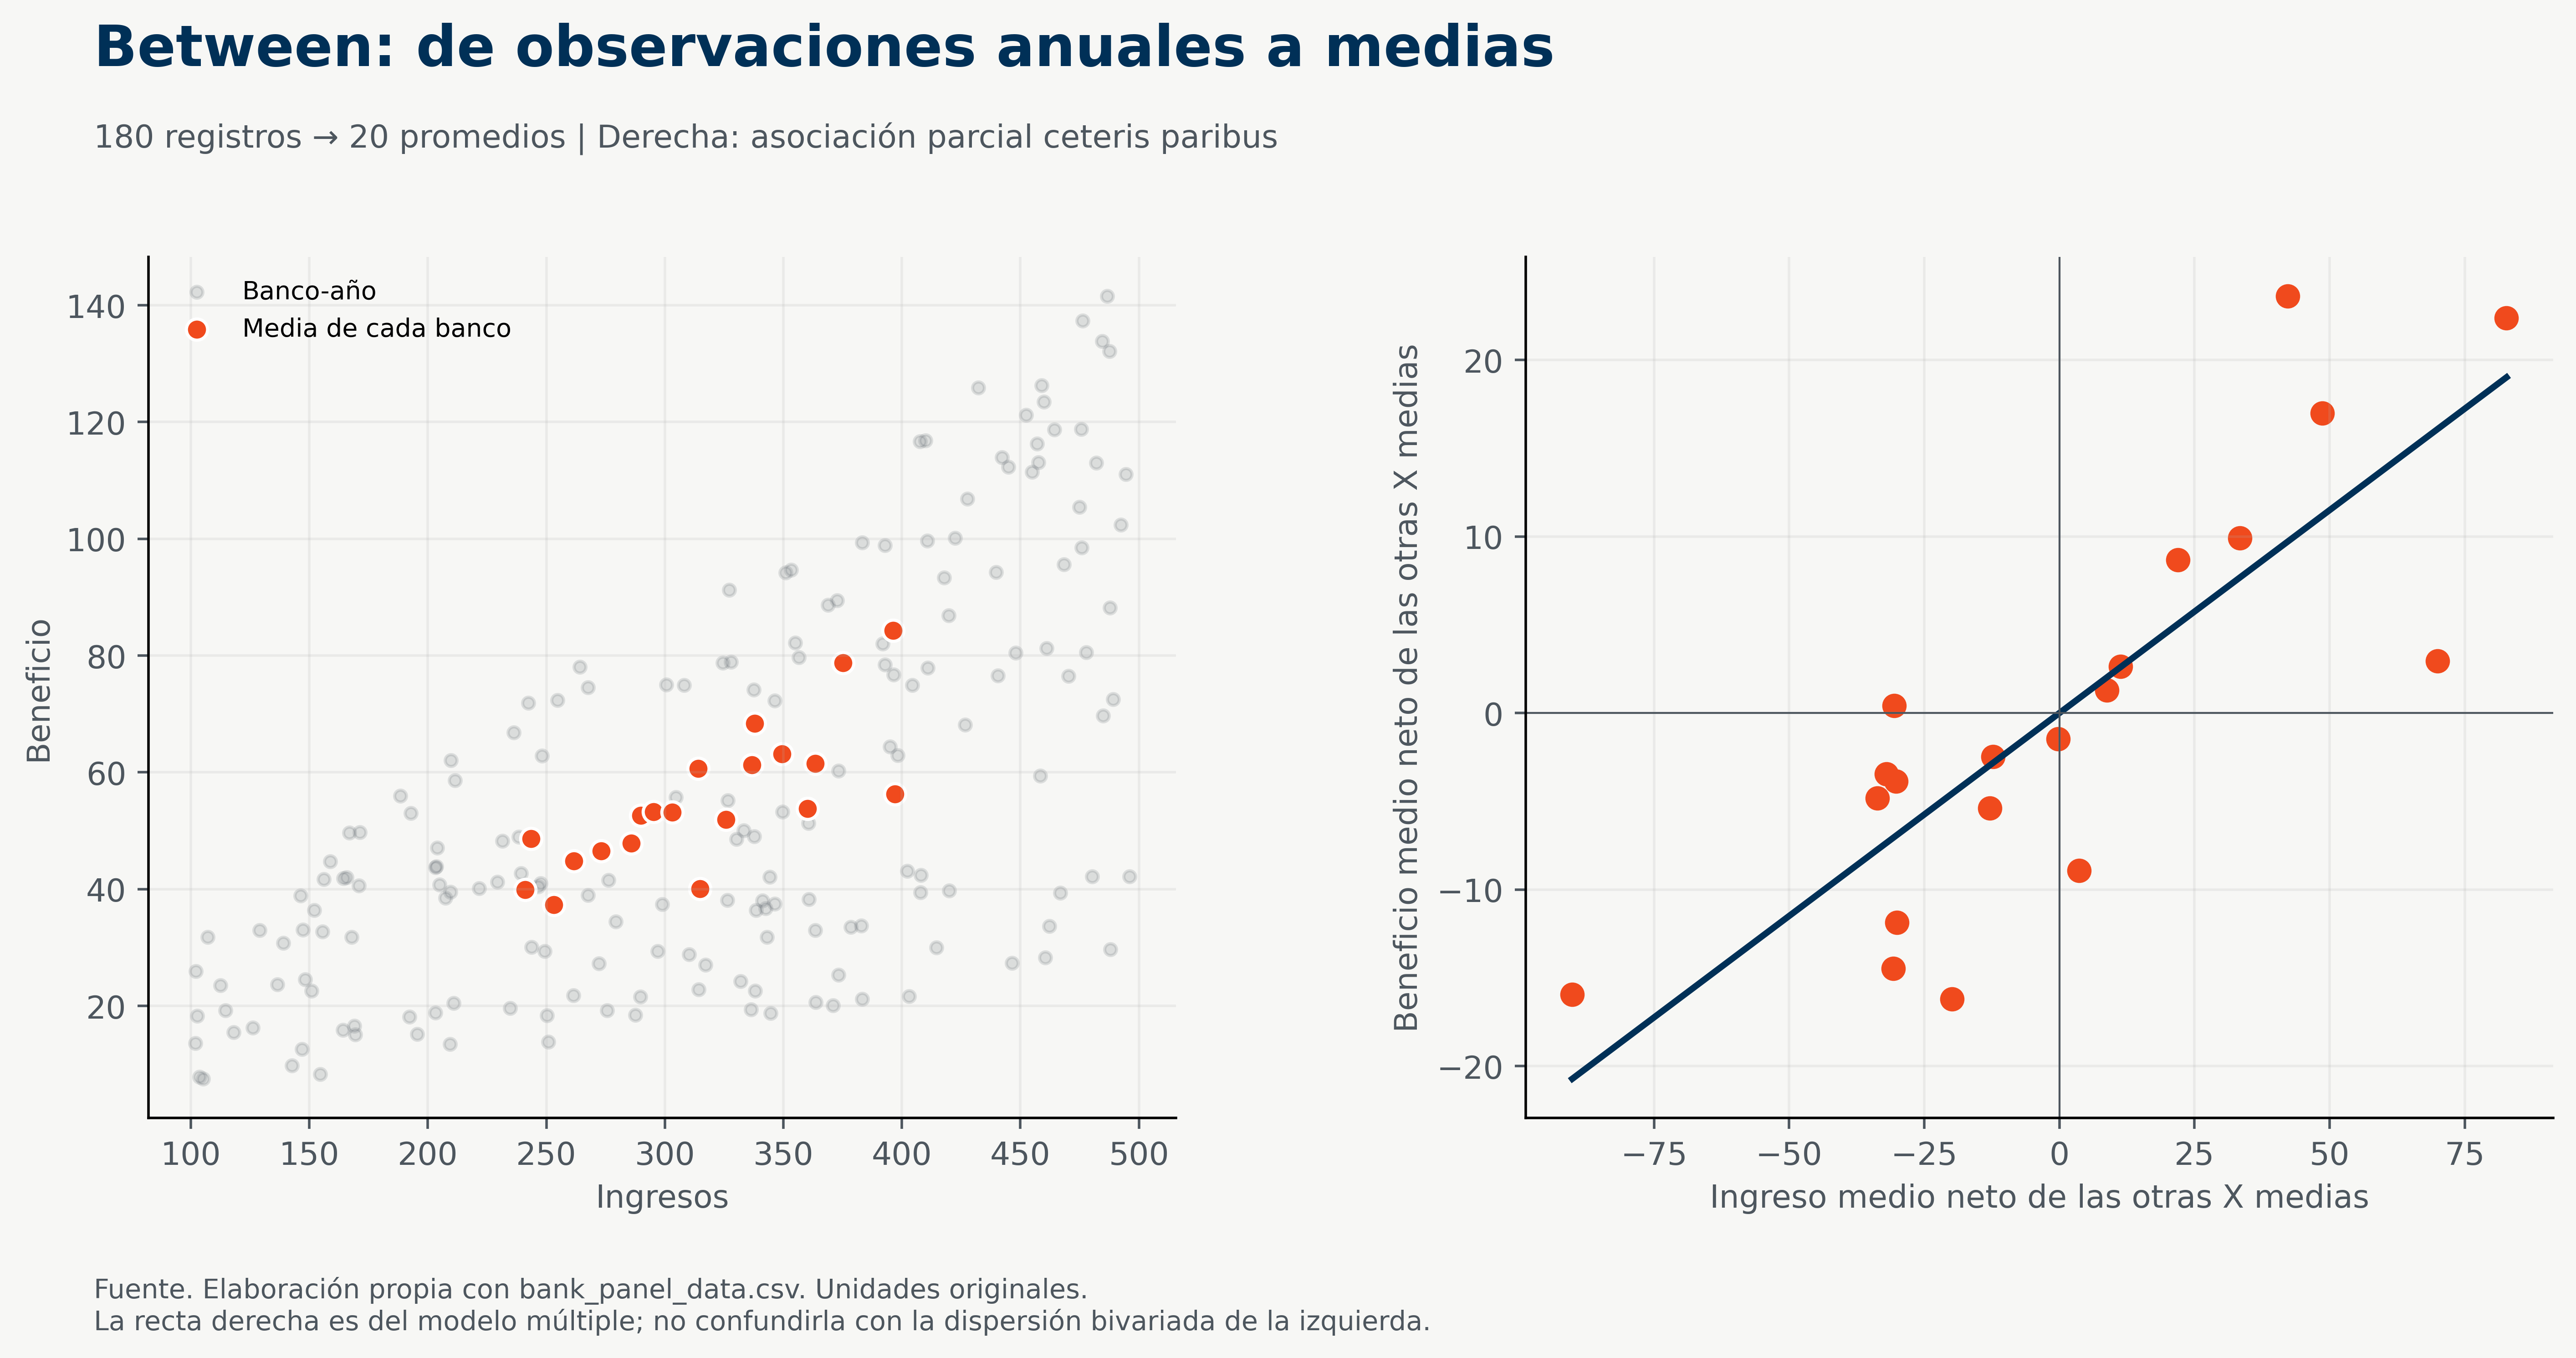

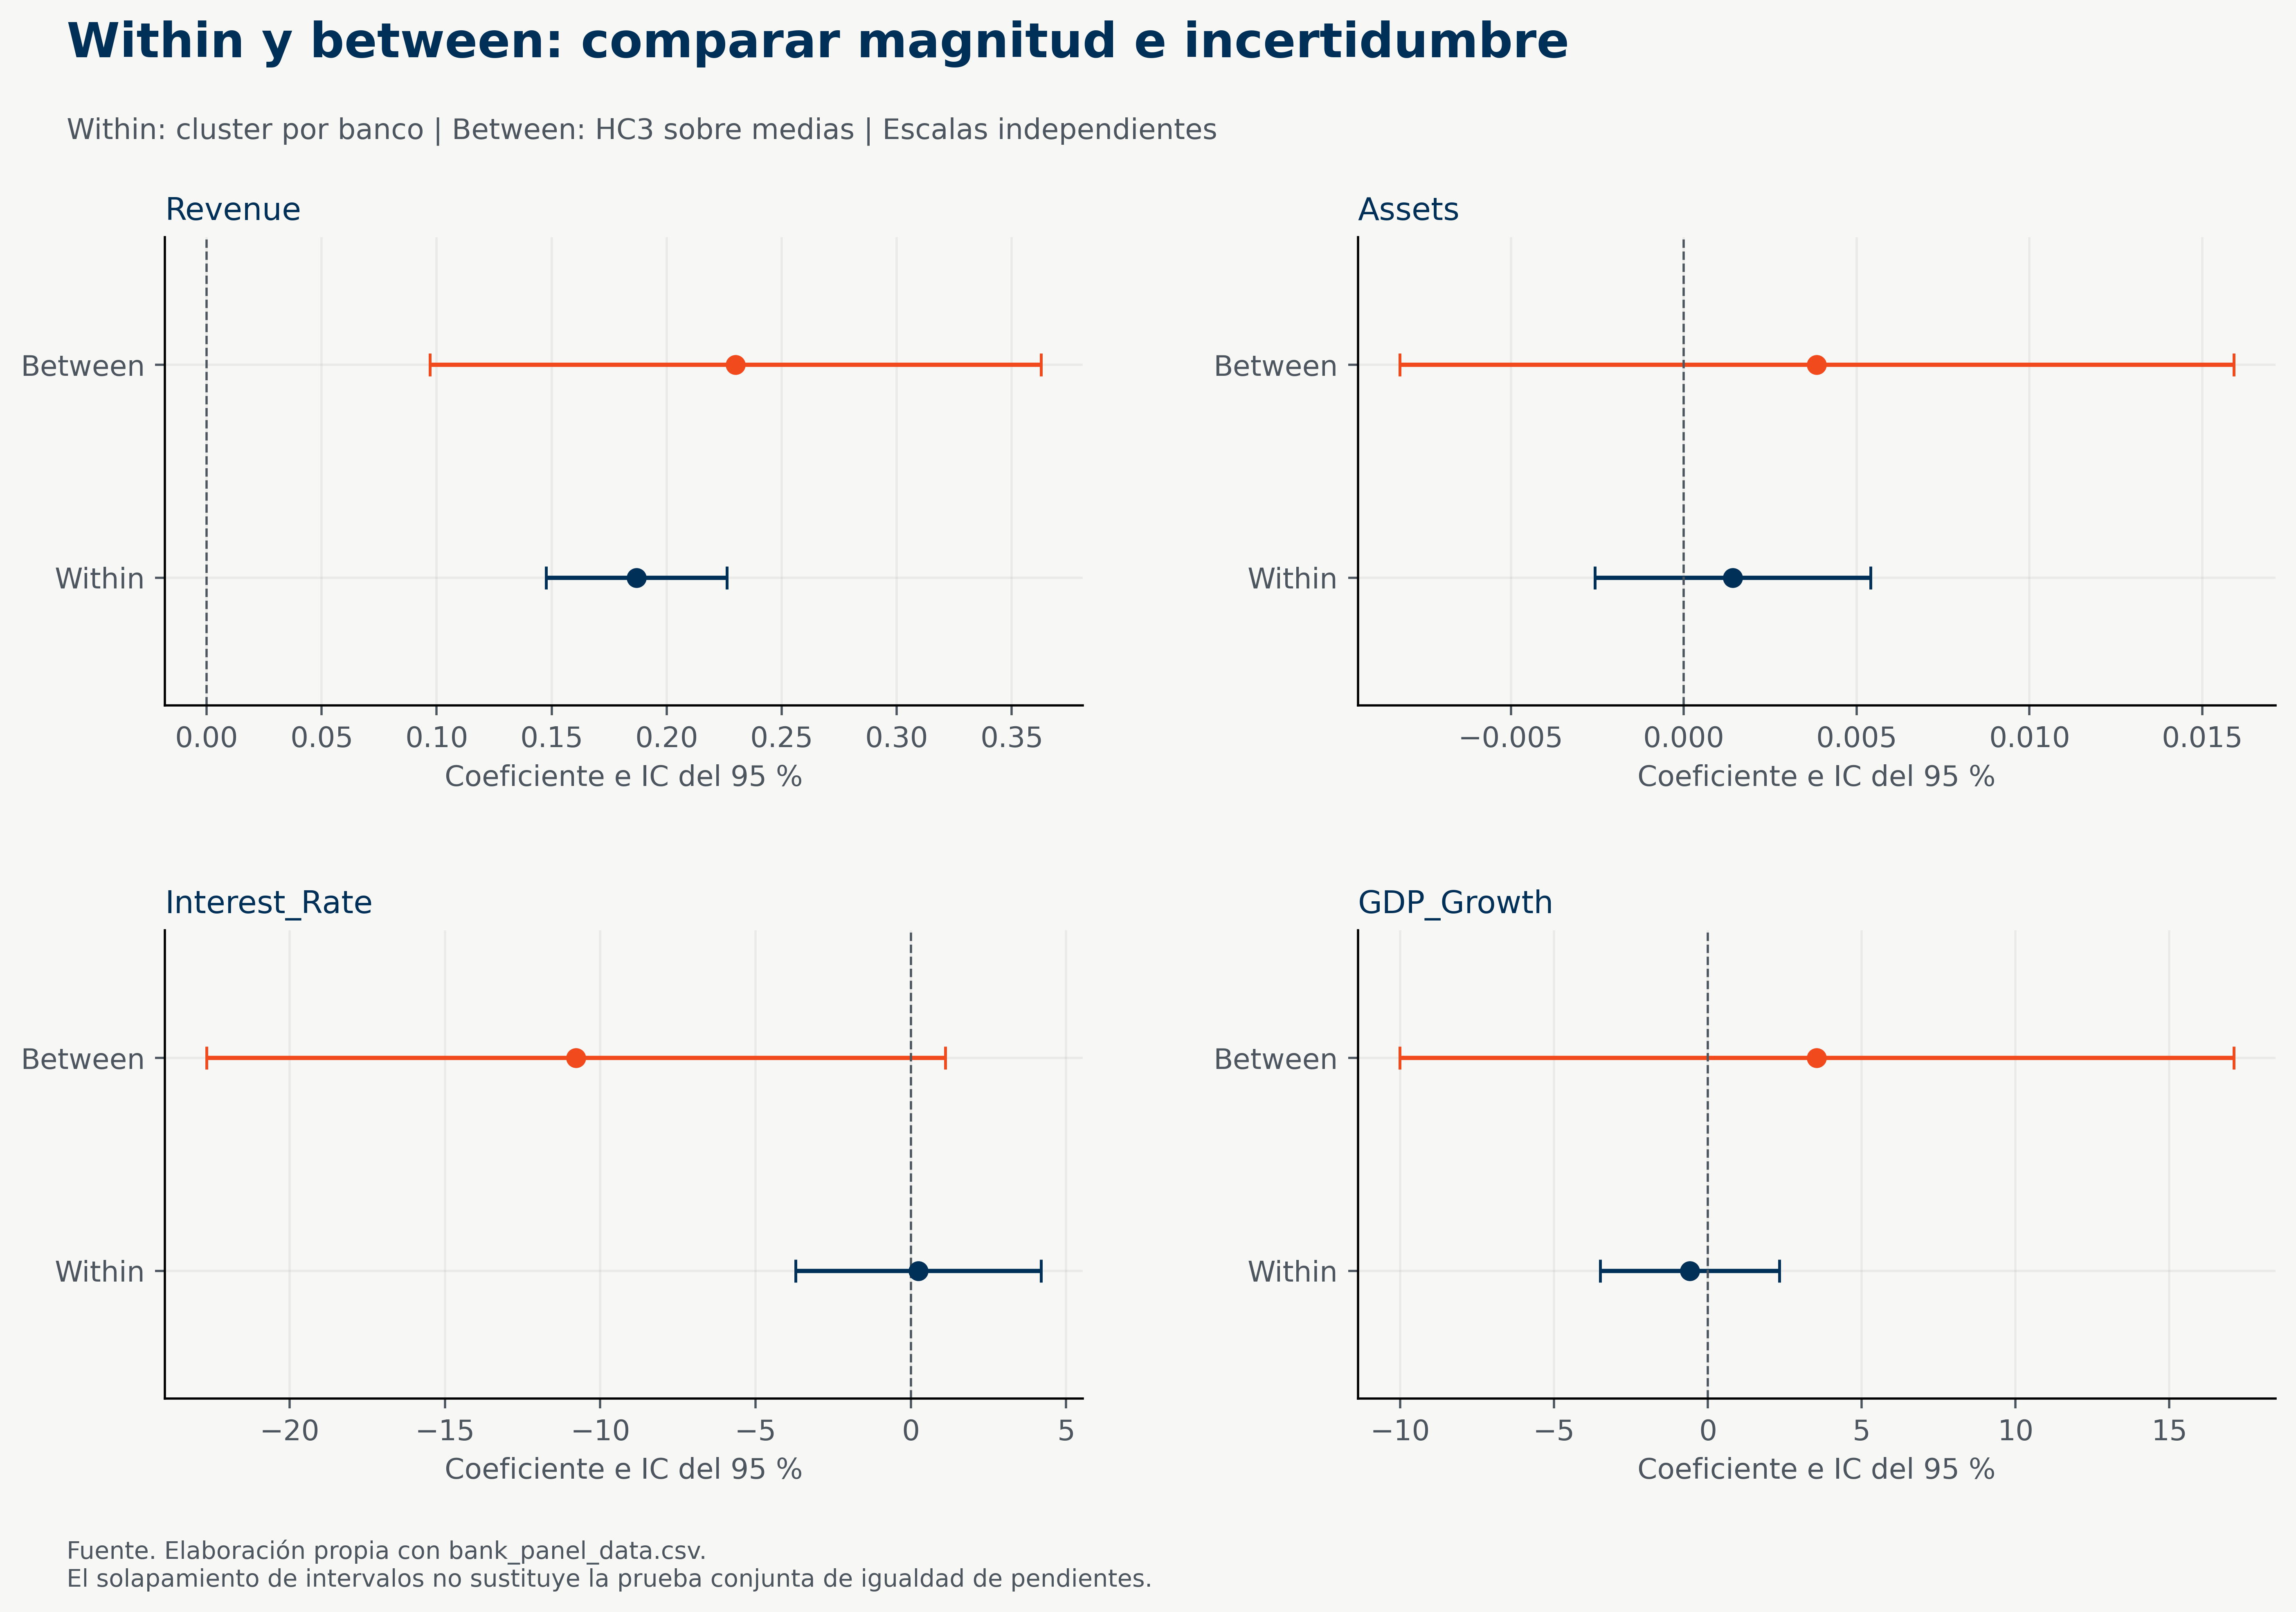

In [13]:
NARANJA,AZUL,GRIS,FONDO="#F04A1D","#003057","#4D565E","#F7F7F5"
plt.rcParams.update({"font.family":"sans-serif","font.sans-serif":["DejaVu Sans"],
    "figure.facecolor":FONDO,"axes.facecolor":FONDO,"axes.labelcolor":GRIS,
    "xtick.color":GRIS,"ytick.color":GRIS,"axes.spines.top":False,
    "axes.spines.right":False,"axes.grid":True,"grid.alpha":.18})
figuras=[]

# Datos anuales y medias; regresión parcial para controlar las otras X ----
fig,axes=plt.subplots(1,2,figsize=(12,6),dpi=500)
axes[0].scatter(Panel.Revenue,Panel.Profit,color=GRIS,alpha=.16,s=14,label="Banco-año")
axes[0].scatter(Medias.Revenue,Medias.Profit,color=NARANJA,s=45,edgecolor="white",label="Media de cada banco")
axes[0].set(xlabel="Ingresos",ylabel="Beneficio");axes[0].legend(frameon=False,fontsize=8)
otros=["const"]+[v for v in explicativas if v!="Revenue"]
rx=sm.OLS(XB.Revenue,XB[otros]).fit().resid
ry=sm.OLS(yB,XB[otros]).fit().resid
parcial=float(rx@ry/(rx@rx));assert np.isclose(parcial,Between_clasico.params.Revenue)
axes[1].scatter(rx,ry,color=NARANJA,s=45)
lim=np.array([rx.min(),rx.max()]);axes[1].plot(lim,parcial*lim,color=AZUL,lw=2)
axes[1].axhline(0,color=GRIS,lw=.6);axes[1].axvline(0,color=GRIS,lw=.6)
axes[1].set(xlabel="Ingreso medio neto de las otras X medias",ylabel="Beneficio medio neto de las otras X medias")
fig.text(.07,.95,"Between: de observaciones anuales a medias",fontsize=18,weight="bold",color=AZUL)
fig.text(.07,.89,f"{NT} registros → {N} promedios | Derecha: asociación parcial ceteris paribus",fontsize=10,color=GRIS)
fig.text(.07,.025,"Fuente. Elaboración propia con bank_panel_data.csv. Unidades originales.\nLa recta derecha es del modelo múltiple; no confundirla con la dispersión bivariada de la izquierda.",fontsize=8.5,color=GRIS)
fig.subplots_adjust(top=.81,bottom=.18,left=.09,right=.97,wspace=.34)
figuras.append(("01_medias",fig))

# Un panel por coeficiente: escalas propias para unidades diferentes ----
fig,axes=plt.subplots(2,2,figsize=(12,8),dpi=500)
ICW=Within_cluster.conf_int().loc[explicativas]
for ax,v in zip(axes.flat,explicativas):
    for j,(nombre,b,ic,color) in enumerate([
        ("Within",Within_cluster.params[v],ICW.loc[v].to_numpy(),AZUL),
        ("Between",Between_HC3.params[v],ICB.loc[v].to_numpy(),NARANJA)]):
        ax.errorbar(b,j,xerr=[[b-ic[0]],[ic[1]-b]],fmt="o",color=color,capsize=4)
    ax.set_yticks([0,1],["Within","Between"]);ax.set_ylim(-.6,1.6)
    ax.axvline(0,color=GRIS,ls="--",lw=.8);ax.set_title(v,loc="left",color=AZUL,fontsize=11)
    ax.set_xlabel("Coeficiente e IC del 95 %")
fig.text(.07,.96,"Within y between: comparar magnitud e incertidumbre",fontsize=17,weight="bold",color=AZUL)
fig.text(.07,.91,"Within: cluster por banco | Between: HC3 sobre medias | Escalas independientes",fontsize=10,color=GRIS)
fig.text(.07,.025,"Fuente. Elaboración propia con bank_panel_data.csv.\nEl solapamiento de intervalos no sustituye la prueba conjunta de igualdad de pendientes.",fontsize=8.5,color=GRIS)
fig.subplots_adjust(top=.85,bottom=.14,left=.11,right=.97,hspace=.48,wspace=.30)
figuras.append(("02_comparacion",fig))